<a href="https://colab.research.google.com/github/Nithya-2-2/MLImaging/blob/practice/Week5_RandomForestClassifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



---



# **Random forest classifier for Cat and Dolphin Image Classification**





---



# Aim

The aim is to classify images of cats and dolphins using a Random Forest classifier. The model learns patterns and features from the image data and uses an ensemble of decision trees to accurately distinguish between the two image classes.

### Objectives

1. Load and preprocess the Cat and Dolphin image dataset.
2. Extract and compare different image features.
3. Split the dataset into training and testing sets
4. Train Random Forest classifiers using different hyperparameter settings.
5. Investigate the effect of hyperparameters such as n_estimators, max_depth and min_samples_split.
6. Evaluate model performance using Accuracy, Precision, Recall, F1-Score and Confusion Matrix.
7. Compare the performance of differnt feature representations and hyperparameter combinations.
8. Analyse underfitting and overfitting by comparing training and testing performance.
9. Identify and justify the best-performing Random Forest model for Cat and Dolphin image Classification.



---



## 1. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import glob
import os, random, warnings
import skimage.filters

from skimage.feature import hog
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier

from skimage import io as skio, color, filters, feature, exposure
from skimage.transform import resize
from pathlib import Path
from skimage.util import img_as_float
from sklearn.model_selection import (train_test_split, StratifiedKFold,cross_val_score,GridSearchCV)


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print('Imports successful.')


Imports successful.


## 2. Loading the Dataset

In [3]:
from google.colab import drive
drive.mount('/content/drive')


SIZE = 128  # Resize all images to this size

#Capture training data and labels into respective lists
images = []
labels = []
image_paths = []


def load_rgb(path,size=(SIZE,SIZE)):
  """ To load the image as RGB numpy array and resize to a new size."""
  img = cv2.imread(path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  img = cv2.resize(img, size)
  return img


# Read the images from the class folders
for directory_path in glob.glob("/content/drive/MyDrive/MLImaging/ML_IPData/*"):
    label = directory_path.split("/")[-1]
    print(label)
    for img_path in glob.glob(os.path.join(directory_path, "*.jpg")):
      img = load_rgb(img_path)
      images.append(img)
      labels.append(label)
      image_paths.append(str(img_path))



images = np.array(images,dtype=np.uint8)
labels = np.array(labels)

print('Total readable images ',len(images))
print('Image array shape',images.shape)

class_counts = pd.Series(labels).value_counts().reindex(['Cat','Dolphin'],fill_value=0)
display(class_counts.rename_axis('Class').to_frame('Image count'))
print(class_counts)


Mounted at /content/drive
Dolphin
Cat
Total readable images  1684
Image array shape (1684, 128, 128, 3)


,Image count
Class,
Cat,869
Dolphin,815


Cat        869
Dolphin    815
Name: count, dtype: int64


## 3. Displaying Sample images from both classes



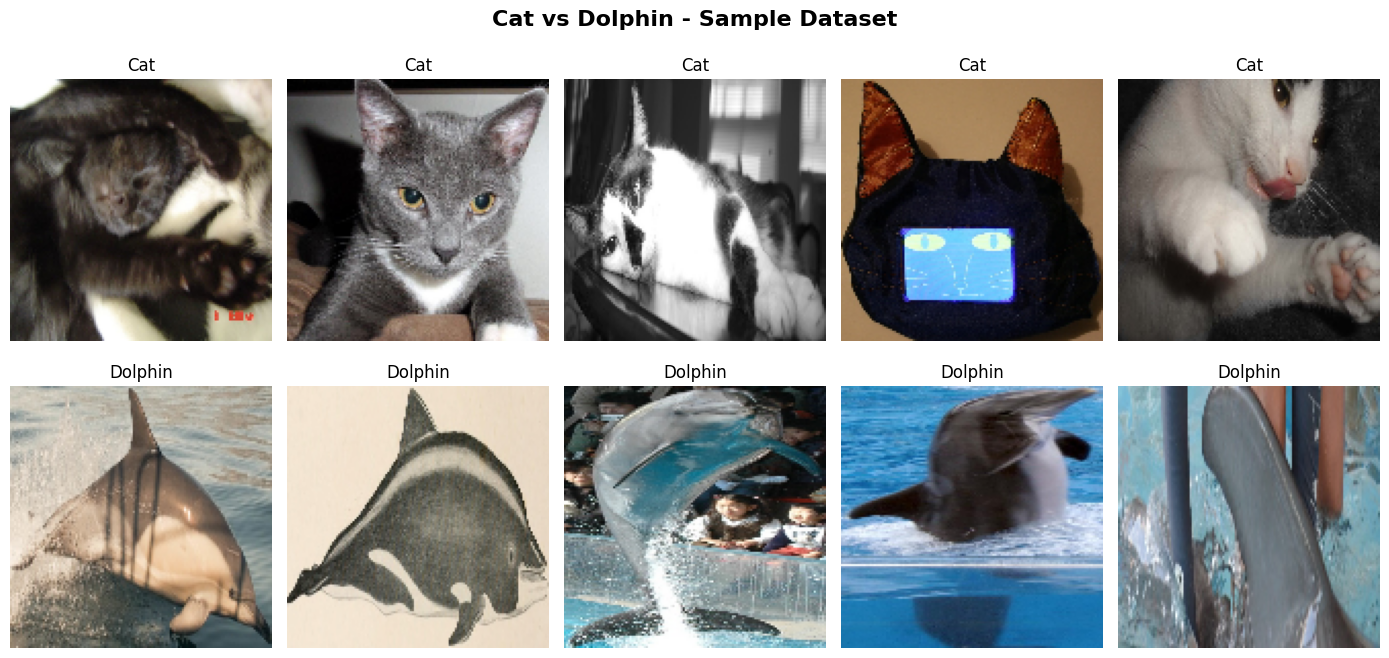

In [4]:
sample_indices = []

for class_name in ['cat','dolphin']:
  class_indices =[
      i for i, label in enumerate(labels)
      if label.lower() == class_name
  ]

  selected_indices = random.sample(class_indices,5)
  sample_indices.extend(selected_indices)


fig,axes = plt.subplots(2,5,figsize=(14,7))

fig.suptitle('Cat vs Dolphin - Sample Dataset',fontsize=16,fontweight='bold')

for i, idx in enumerate(sample_indices):
  img = images[idx]
  label = labels[idx]

  row = i // 5
  col = i % 5
  axes[row,col].imshow(img)
  axes[row,col].set_title(label)
  axes[row,col].axis('off')


plt.tight_layout()
plt.show()

## 4. Label mapping and Stratified Train/Test split

In [5]:
label_mapping = {'Cat': 0, 'Dolphin': 1}
y = np.array([label_mapping[label] for label in labels])

indices = np.arange(len(y))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=SEED, stratify=y)

y_train = y[train_idx]
y_test = y[test_idx]

print('Training images:', len(train_idx))
print("Test images:", len(test_idx))
print("Training class counts:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Test class counts:", dict(zip(*np.unique(y_test, return_counts=True))))

Training images: 1347
Test images: 337
Training class counts: {np.int64(0): np.int64(695), np.int64(1): np.int64(652)}
Test class counts: {np.int64(0): np.int64(174), np.int64(1): np.int64(163)}


## 5. Feature Extraction

* Feature 1: Raw Pixels

In [6]:
X_pixels = []

for img in images:
  X_pixels.append(img.flatten())

X_pixels = np.array(X_pixels)
print('Raw pixel feature matrix: ',X_pixels.shape)

Raw pixel feature matrix:  (1684, 49152)




*  Feature 2: HOG Features



In [7]:
hog_features =[]

for img in images:
  gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
  fd = hog(gray,orientations=9,pixels_per_cell=(8,8),cells_per_block=(2,2))
  hog_features.append(fd)

X_hog = np.array(hog_features)
print('HOG feature matrix: ',X_hog.shape)

HOG feature matrix:  (1684, 8100)


* Feature 3: Color Statistics

In [8]:
color_features = []

for img in images:
  mean_rgb = np.mean(img,axis=(0,1))
  std_rgb = np.std(img,axis=(0,1))

  feature = np.concatenate([mean_rgb,std_rgb])
  color_features.append(feature)

X_color = np.array(color_features)

print('Colour-Statistics feature matrix: ',X_color.shape)

Colour-Statistics feature matrix:  (1684, 6)


* 5b. Feature comparison using Cross validation on the training data

In [9]:
feature_sets = {
    'Raw Pixels': X_pixels,
    'HOG Features': X_hog,
    'Color Statistics': X_color
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
feature_cv_results = []

for feature_name, X in feature_sets.items():
  X_train_feature = X[train_idx]

  baseline = RandomForestClassifier(n_estimators=50, criterion='gini', random_state=SEED, n_jobs=-1)
  baseline_scores = cross_val_score(baseline, X_train_feature, y_train, cv=cv, scoring='f1_macro', n_jobs=1)
  feature_cv_results.append({
      'Feature set': feature_name,
      'Mean F1-Score': baseline_scores.mean(),
      'Std F1-Score': baseline_scores.std(),
      'Number of features': X.shape[1]
  })

feature_cv_table = pd.DataFrame(feature_cv_results).sort_values(by='Mean F1-Score', ascending=False).reset_index(drop=True)

display(feature_cv_table.round(4))
best_feature_name = feature_cv_table.loc[0, 'Feature set']

X_selected = feature_sets[best_feature_name]
X_train_selected = X_selected[train_idx]
X_test_selected = X_selected[test_idx]

print(f'Feature set selected using training cross-validation: {best_feature_name}')

,Feature set,Mean F1-Score,Std F1-Score,Number of features
0,Color Statistics,0.8708,0.0054,6
1,Raw Pixels,0.8310,0.0118,49152
2,HOG Features,0.7228,0.0040,8100


Feature set selected using training cross-validation: Color Statistics


## 6. Random Forest Evaluation Function

In [10]:
def evaluate_RandomForest(X,name):
  X_train = X[train_idx]
  X_test = X[test_idx]

  #Baseline Random Forest
  rf_classifier = RandomForestClassifier(n_estimators=100, criterion='gini', random_state=42)
  rf_classifier.fit(X_train, y_train)

  train_pred = rf_classifier.predict(X_train)
  test_pred = rf_classifier.predict(X_test)
  train_accuracy = rf_classifier.score(X_train, y_train)
  test_accuracy = rf_classifier.score(X_test, y_test)

  precision = precision_score(y_test, test_pred, average='macro', zero_division=0)
  recall = recall_score(y_test, test_pred, average='macro', zero_division=0)
  f1 = f1_score(y_test, test_pred, average='macro', zero_division=0)

  print(f"\n{'~' * 60}")
  print(f"Random Forest Baseline: {name}")
  print('~' * 60)
  print(f"Training Accuracy: {train_accuracy:.4f}")
  print(f"Testing Accuracy:  {test_accuracy:.4f}")
  print(f"Macro Precision:   {precision:.4f}")
  print(f"Macro Recall:      {recall:.4f}")
  print(f"Macro F1-score:    {f1:.4f}")

  print("\nClassification Report:")
  print(classification_report(y_test, test_pred,labels =[0,1],target_names=['Cat', 'Dolphin'], zero_division=0))

  cm = confusion_matrix(y_test, test_pred,labels=[0,1])
  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_classifier.classes_)
  disp.plot(cmap=plt.cm.Blues)
  plt.title(f"Random Forest — {name}")
  plt.show()

  return {
        'Feature Set': name,
        'Train Accuracy': train_accuracy,
        'Test Accuracy': test_accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'Model': rf_classifier
    }

## 7. Testing the Features with Random Forest Classifier

* Raw Pixels


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Random Forest Baseline: Raw Pixels
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Training Accuracy: 1.0000
Testing Accuracy:  0.8576
Macro Precision:   0.8659
Macro Recall:      0.8551
Macro F1-score:    0.8560

Classification Report:
              precision    recall  f1-score   support

         Cat       0.82      0.93      0.87       174
     Dolphin       0.91      0.78      0.84       163

    accuracy                           0.86       337
   macro avg       0.87      0.86      0.86       337
weighted avg       0.86      0.86      0.86       337



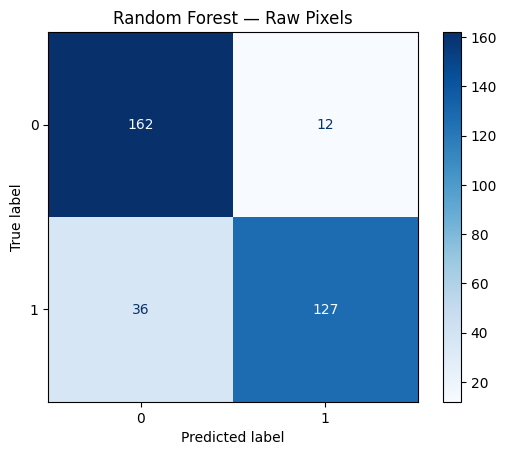

In [11]:
pixel_results = evaluate_RandomForest(X_pixels,'Raw Pixels')

* HOG Features


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Random Forest Baseline: HOG Features
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Training Accuracy: 1.0000
Testing Accuracy:  0.7893
Macro Precision:   0.7897
Macro Recall:      0.7884
Macro F1-score:    0.7887

Classification Report:
              precision    recall  f1-score   support

         Cat       0.78      0.82      0.80       174
     Dolphin       0.79      0.76      0.78       163

    accuracy                           0.79       337
   macro avg       0.79      0.79      0.79       337
weighted avg       0.79      0.79      0.79       337



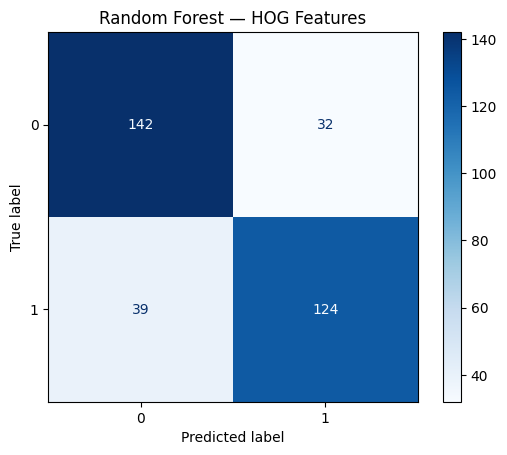

In [12]:
hog_results = evaluate_RandomForest(X_hog,'HOG Features')

* Color Statistics


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Random Forest Baseline: Color Statistics
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Training Accuracy: 0.9993
Testing Accuracy:  0.8872
Macro Precision:   0.8915
Macro Recall:      0.8856
Macro F1-score:    0.8865

Classification Report:
              precision    recall  f1-score   support

         Cat       0.86      0.94      0.90       174
     Dolphin       0.93      0.83      0.88       163

    accuracy                           0.89       337
   macro avg       0.89      0.89      0.89       337
weighted avg       0.89      0.89      0.89       337



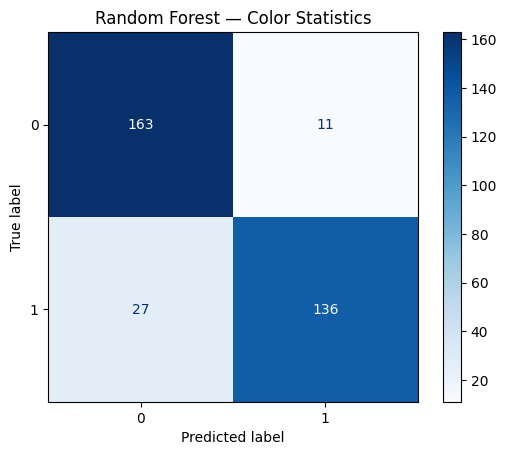

In [13]:
color_results = evaluate_RandomForest(X_color,'Color Statistics')

## 8. Comparing the baseline results in one table

In [14]:
all_baseline_results = [
    pixel_results,
    hog_results,
    color_results
]

baseline_table = pd.DataFrame([
    {key: value for key, value in result.items()
     if key != 'Model'}
    for result in all_baseline_results
])

baseline_table = baseline_table.sort_values(
    by='F1-score',
    ascending=False
).reset_index(drop=True)

baseline_table.round(4)

,Feature Set,Train Accuracy,Test Accuracy,Precision,Recall,F1-score
0,Color Statistics,0.9993,0.8872,0.8915,0.8856,0.8865
1,Raw Pixels,1.0000,0.8576,0.8659,0.8551,0.8560
2,HOG Features,1.0000,0.7893,0.7897,0.7884,0.7887


## 9. Hyperparameter Investigation / Tuning

* Finding the best feature set for tuning



In [15]:
feature_sets = {
    'Raw Pixels': X_pixels,
    'HOG Features': X_hog,
    'Color Statistics': X_color
}

best_feature_name = baseline_table.iloc[0]['Feature Set']
X_best = feature_sets[best_feature_name]
X_train_best = X_best[train_idx]
X_test_best = X_best[test_idx]

print(f'Feature set selected using training cross-validation for tuning: {best_feature_name}')

Feature set selected using training cross-validation for tuning: Color Statistics


* Using GridSearchCV to investigate the below hyperparameters:

   - criterion: Gini vs Entropy
   - n_estimators: number of trees
   - max_depth: maximum depth of each tree


In [16]:
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

param_grid = {
    'criterion': ['gini', 'entropy'],
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

grid_search.fit(X_train_best, y_train)

print("Best hyperparameters:")
print(grid_search.best_params_)

print(f"\nBest cross-validation macro F1: "
      f"{grid_search.best_score_:.4f}")

Best hyperparameters:
{'criterion': 'gini', 'max_depth': 10, 'n_estimators': 100}

Best cross-validation macro F1: 0.8753


* The hyperparameter Comparison results

In [17]:
tuning_results = pd.DataFrame(grid_search.cv_results_)

tuning_table = tuning_results[[
    'param_criterion',
    'param_n_estimators',
    'param_max_depth',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]].copy()

tuning_table = tuning_table.rename(columns={
    'param_criterion': 'Criterion',
    'param_n_estimators': 'Number of Trees',
    'param_max_depth': 'Maximum Depth',
    'mean_train_score': 'Mean Training CV F1',
    'mean_test_score': 'Mean Validation CV F1',
    'std_test_score': 'Validation F1 Std'
})

tuning_table = tuning_table.sort_values(
    by='Mean Validation CV F1',
    ascending=False
).reset_index(drop=True)

tuning_table.round(4)

,Criterion,Number of Trees,Maximum Depth,Mean Training CV F1,Mean Validation CV F1,Validation F1 Std
0,gini,100,10,0.9933,0.8753,0.0104
1,gini,100,20,1.0000,0.8746,0.0108
2,gini,100,None,1.0000,0.8746,0.0108
3,entropy,100,10,0.9907,0.8730,0.0127
4,gini,200,20,1.0000,0.8716,0.0067
5,gini,200,None,1.0000,0.8716,0.0067
6,gini,50,20,1.0000,0.8708,0.0054
7,gini,50,None,1.0000,0.8708,0.0054
8,gini,50,10,0.9937,0.8701,0.0078
9,entropy,200,10,0.9933,0.8700,0.0108


## 10. Evaluating the final best model

FINAL RANDOM FOREST MODEL
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Feature set: Color Statistics
Best parameters: {'criterion': 'gini', 'max_depth': 10, 'n_estimators': 100}
Training Accuracy: 0.9866
Testing Accuracy:  0.8872
Macro Precision:   0.8915
Macro Recall:      0.8856
Macro F1-score:    0.8865

Classification Report:
              precision    recall  f1-score   support

         Cat       0.86      0.94      0.90       174
    Dolphins       0.93      0.83      0.88       163

    accuracy                           0.89       337
   macro avg       0.89      0.89      0.89       337
weighted avg       0.89      0.89      0.89       337



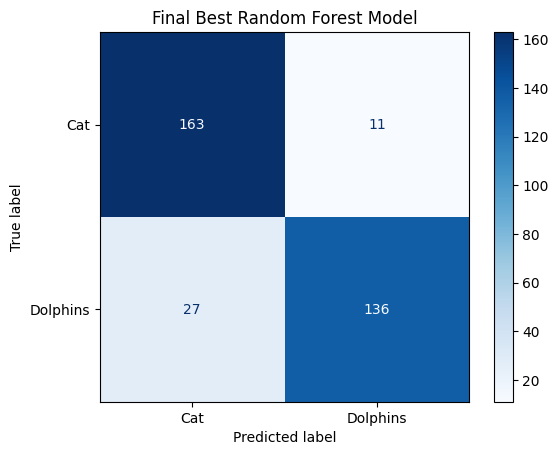

In [18]:
best_model = grid_search.best_estimator_

# Predictions on training and test data
final_train_pred = best_model.predict(X_train_best)
final_test_pred = best_model.predict(X_test_best)

# Metrics
final_train_accuracy = accuracy_score(
    y_train, final_train_pred
)

final_test_accuracy = accuracy_score(
    y_test, final_test_pred
)

final_precision = precision_score(
    y_test, final_test_pred,
    average='macro',
    zero_division=0
)

final_recall = recall_score(
    y_test, final_test_pred,
    average='macro',
    zero_division=0
)

final_f1 = f1_score(
    y_test, final_test_pred,
    average='macro',
    zero_division=0
)

print("FINAL RANDOM FOREST MODEL")
print("~" * 60)
print("Feature set:", best_feature_name)
print("Best parameters:", grid_search.best_params_)
print(f"Training Accuracy: {final_train_accuracy:.4f}")
print(f"Testing Accuracy:  {final_test_accuracy:.4f}")
print(f"Macro Precision:   {final_precision:.4f}")
print(f"Macro Recall:      {final_recall:.4f}")
print(f"Macro F1-score:    {final_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_test_pred,
    labels=[0, 1],
    target_names=['Cat','Dolphins'],
    zero_division=0
))

cm = confusion_matrix(y_test, final_test_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Cat','Dolphins']
)

disp.plot(cmap=plt.cm.Blues)
plt.title('Final Best Random Forest Model')
plt.show()

## 11. Underfitting and Overfitting Analysis

In [19]:
accuracy_gap = final_train_accuracy - final_test_accuracy

print('Underfitting and Overfitting Analysis')
print('~' * 60)
print(f'Training Accuracy: {final_train_accuracy:.4f}')
print(f'Testing Accuracy: {final_test_accuracy:.4f}')
print(f'Accuracy Gap: {accuracy_gap:.4f}')

if accuracy_gap > 0.10:
  print('The model is overfitting.')
  print('Training performance is substantially higher than test performance')
elif final_train_accuracy <0.70 and final_test_accuracy < 0.70:
  print('The model is underfitting.')
  print('Both training and test performance are relatively low')
else:
  print('The model is neither overfitting nor underfitting.')
  print('Some overfitting, although the cross validation results should also be considered.')

Underfitting and Overfitting Analysis
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Training Accuracy: 0.9866
Testing Accuracy: 0.8872
Accuracy Gap: 0.0994
The model is neither overfitting nor underfitting.
Some overfitting, although the cross validation results should also be considered.


## 12. Model Summary table

In [20]:
final_summary = pd.DataFrame([{
    'Feature Set': best_feature_name,
    'Criterion': grid_search.best_params_['criterion'],
    'Number of Trees': grid_search.best_params_['n_estimators'],
    'Maximum Depth': str(grid_search.best_params_['max_depth']),
    'CV Macro F1': grid_search.best_score_,
    'Train Accuracy': final_train_accuracy,
    'Test Accuracy': final_test_accuracy,
    'Macro Precision': final_precision,
    'Macro Recall': final_recall,
    'Macro F1': final_f1,
    'Accuracy Gap': accuracy_gap
}])

final_summary.round(4)

,Feature Set,Criterion,Number of Trees,Maximum Depth,CV Macro F1,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Accuracy Gap
0,Color Statistics,gini,100,10,0.8753,0.9866,0.8872,0.8915,0.8856,0.8865,0.0994


# 13. Conclusion



---



The three feature extraction methods - Raw Pixels, HOG features and colour statistics - were evaluated using the Random Forest classifier to distinguish cats from dolphins.

Color Statistics achieved the highest macro F1 score of 87.53% amongst the other features, making it the best performing feature set.

Hyperparameter tuning identified the best configuration as Gini criterion, max_depth =10 and n_estimators = 100,achieving a cross validation macro F1 score of 88.65% and test accuracy of 88.72%.

The final model achieved a prediction accuracy of 93.68% for the cat images and 83.44% for dolphin images. The class-wise results indicates how effectively the model identifies each animal and whether one class is more frequently misclassified than the other.

The observed accuracy gap between the training and testing performance was 0.0994 indicating a noticeable difference between the training and test performance. This may suggest some overfitting, although the cross validation results should also be considered. The gap alone is not sufficient to determine whether the model is overfitting or underfitting.

Overall, the selected feature set and tuned Random Forest configuration provided the best performance among the configurations evaluated.

In [23]:
# Calculate individual prediction accuracy for each animal
individual_accuracy = cm.diagonal() / cm.sum(axis=1) * 100

class_names = ['Cat', 'Dolphin']

print("INDIVIDUAL CLASS PREDICTION ACCURACY")
print("-" * 45)

for i, animal in enumerate(class_names):
    print(f"{animal} Prediction Accuracy: {individual_accuracy[i]:.2f}%")

INDIVIDUAL CLASS PREDICTION ACCURACY
---------------------------------------------
Cat Prediction Accuracy: 93.68%
Dolphin Prediction Accuracy: 83.44%




---





---



## -- Checking

11b. Further Investigation on Overfitting

*   Overfitting Reduction Experiment - Reducing model complexity
*  - To investigate whether overfitting can be reduced by limiting tree depth and by increasing the minimum number of samples required at a leaf.



In [21]:
overfit_grid = {
    'max_depth': [3, 5, 8, 10, None],
    'min_samples_leaf': [1, 2, 4],
    'n_estimators': [100]
}

overfit_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        criterion=grid_search.best_params_['criterion'],
        random_state=SEED,
        n_jobs=-1
    ),
    param_grid=overfit_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

overfit_grid_search.fit(X_train_selected, y_train)

overfit_results = pd.DataFrame(overfit_grid_search.cv_results_)

overfit_table = overfit_results[[
    'param_max_depth',
    'param_min_samples_leaf',
    'mean_train_score',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]].sort_values(
    by='rank_test_score',
    ascending=True
).reset_index(drop=True)

overfit_table = overfit_table.rename(columns={
    'param_max_depth': 'Maximum Depth',
    'param_min_samples_leaf': 'Minimum Samples per Leaf',
    'mean_train_score': 'Mean Training CV F1',
    'mean_test_score': 'Mean Validation CV F1',
    'std_test_score': 'Validation F1 Std'
})

display(overfit_table.round(4))

print('Best parameters for the overfitting-reduction experiment:')
print(overfit_grid_search.best_params_)

print('Best cross-validation macro F1: ',round(overfit_grid_search.best_score_,4))




,Maximum Depth,Minimum Samples per Leaf,Mean Training CV F1,Mean Validation CV F1,Validation F1 Std,rank_test_score
0,10,1,0.9933,0.8753,0.0104,1
1,None,1,1.0000,0.8746,0.0108,2
2,None,4,0.9497,0.8731,0.0120,3
3,10,4,0.9471,0.8724,0.0125,4
4,8,1,0.9710,0.8715,0.0121,5
5,8,2,0.9605,0.8707,0.0136,6
6,10,2,0.9736,0.8686,0.0109,7
7,8,4,0.9389,0.8662,0.0088,8
8,None,2,0.9848,0.8648,0.0115,9
9,5,1,0.9156,0.8557,0.0162,10


Best parameters for the overfitting-reduction experiment:
{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}
Best cross-validation macro F1:  0.8753


* Comparing the Original Model with the simpler model experiment

In [22]:
original_cv_f1 = grid_search.best_score_
overfit_exp_cv_f1 = overfit_grid_search.best_score_

print('Overfitting reduction comparison')
print('~'*60)
print(f'Original model cross-validation macro F1: {original_cv_f1:.4f}')
print(f'Overfitting reduction cross-validation macro F1: {overfit_exp_cv_f1:.4f}')
print(f'Cross-validation macro F1 difference: {overfit_exp_cv_f1 - original_cv_f1:.4f}')

if overfit_exp_cv_f1 > original_cv_f1:
  print('The reduction experiment achieved a higher cross-validation macro f1 and the overfitting reduction experiment improved the model.')
elif overfit_exp_cv_f1 == original_cv_f1:
  print('The cross-validation macro F1 is unchanged and the overfitting reduction experiment did not improve the model.')
else:
  print('The overfitting reduction experiment did not improve the model.')

Overfitting reduction comparison
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Original model cross-validation macro F1: 0.8753
Overfitting reduction cross-validation macro F1: 0.8753
Cross-validation macro F1 difference: 0.0000
The cross-validation macro F1 is unchanged and the overfitting reduction experiment did not improve the model.
